# TripletMarginLoss-NetlistGraph-node_type

这是使用网表图+独立卷积层的新版本

In [1]:
import os, sys, itertools
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from hw2vec.config import Config
from hw2vec.hw2graph import *
from tqdm import tqdm
from pytorch_metric_learning import distances, losses, miners, reducers

/home/heyiran/.conda/envs/HWsim/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# dir = ['--yaml_path', '../config/example_gnn4ip.yaml', \
#     #    '--raw_dataset_path', '../../bigcreate/newdatas', \
#     #    '--data_pkl_path', 'pkl/dfg_ip_rt291.pkl', \
#         '--graph_type', 'DFG']
dir = ['--yaml_path', '../config/example_gnn4ip.yaml']
# cfg = Config(sys.argv[1:])
cfg = Config(dir)

In [3]:
cfg.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
cfg.num_feature_dim = 10
cfg.batch_size = 64
cfg.hidden1 = 64
cfg.hidden2 = 128
cfg.embed_dim = 256
# cfg.epochs = 200
# cfg.epochs = 100
cfg.epochs = 300
# cfg.epochs = 400
# cfg.learning_rate = 0.001
cfg.learning_rate = 0.01
# cfg.learning_rate = 0.05
cfg.dropout = 0.1




## 0 加载数据集

In [4]:
# dataset = torch.load("Reduced-DFG-with_big.pt")
# dataset = torch.load("Reduced-DFG.pt")
dataset = torch.load("NetlistGraph-node_type.pt")

In [5]:
sim_diff_label = []
for data in dataset:
    sim_diff_label.append(data.label)

别忘了把数据放到GPU！

In [6]:
for data in dataset:
    data = data.to(cfg.device)

In [7]:
trainset, testset = train_test_split(dataset, \
                                     train_size = int(len(dataset) * cfg.ratio), \
                                     shuffle=True, \
                                     #  stratify=None, \
                                     stratify=sim_diff_label, \
                                     random_state=cfg.seed)

In [8]:
len(trainset)

244

In [9]:
len(testset)

61

---

构造训练集（`train_loader`）：

In [10]:
# train_loader = DataLoader(trainset, shuffle=True, batch_size=cfg.batch_size)
train_loader = DataLoader(dataset, shuffle=True, batch_size=cfg.batch_size)  # testset used during training

---

构造测试集（`test_loader`）：

测试集中的图完全没有在训练时出现过

In [11]:
test_pairs = []
for idx_graph_a, idx_graph_b in itertools.combinations(range(len(testset)), 2):  # testset
    test_pairs.append((testset[idx_graph_a], testset[idx_graph_b]))

SIMILAR = torch.tensor(1, device=cfg.device)
DISSIMILAR = torch.tensor(-1, device=cfg.device)
for pair_idx, pair in enumerate(test_pairs):
    # print(type(all_pairs))
    graph_a, graph_b = pair
    # print(all_pairs[pair_idx], graph_a.hw_type, graph_b.hw_type)
    if graph_a.label == graph_b.label:
        test_pairs[pair_idx] += (SIMILAR,)
    else:
        test_pairs[pair_idx] += (DISSIMILAR,)

In [12]:
test_pairs[0]

(Data(edge_index=[2, 424], x=[284, 10], label=4, type='c432', name='c432-SL320', node_type=[284]),
 Data(edge_index=[2, 4432], x=[3317, 10], label=2, type='c2670', name='c2670-NR7630', node_type=[3317]),
 tensor(-1, device='cuda:0'))

In [13]:
test_loader = DataLoader(test_pairs, batch_size=cfg.batch_size)

## 1 定义模型

节点独立GCN

In [14]:
model = GRAPH2VEC(cfg)
convs = [
    GRAPH_CONV("gcn", cfg.num_feature_dim, cfg.hidden1),  # 前者是标签数量，后者是隐藏层
    # GRAPH_CONV("gcn", cfg.hidden, cfg.hidden),
    GRAPH_CONV("gcn", cfg.hidden1, cfg.hidden2)
]
# model.set_graph_conv(convs)
model.set_graph_conv_node_type(convs)

readout = GRAPH_READOUT("mean")
model.set_graph_readout(readout)

output = nn.Linear(cfg.hidden2, cfg.embed_dim)
model.set_output_layer(output)


加载模型参数

In [15]:
# model.load_state_dict(torch.load("triplet_model_notestset.pt"))
model.load_state_dict(torch.load("triplet_model_circuitgraph_node_type_good.pt"))

<All keys matched successfully>

In [16]:
model.to(cfg.device)
trainer = PairwiseGraphTrainer(cfg)
trainer.build(model)


## 2 训练

In [17]:
cfg.trainer = 'triplet'
# cfg.epochs = 100
# cfg.epochs = 400
# trainer.triplet_train_node_type(train_loader, mining='hard', margin=0.2)
trainer.triplet_train_node_type(train_loader, mining='semihard', margin=0.2)

  0%|          | 0/300 [00:00<?, ?it/s]

Epoch 0 Iteration 0: Loss = 0.16762377321720123, Number of mined triplets = 18409
Epoch 0 Iteration 1: Loss = 0.12345761060714722, Number of mined triplets = 9013


Epoch 0 Iteration 2: Loss = 0.12467967718839645, Number of mined triplets = 6176


  0%|          | 1/300 [00:01<07:45,  1.56s/it]

Epoch 0 Iteration 3: Loss = 0.12416359782218933, Number of mined triplets = 5182
Epoch 0 Iteration 4: Loss = 0.11530295014381409, Number of mined triplets = 2315


...

Epoch 280 Iteration 2: Loss = 0.08776390552520752, Number of mined triplets = 2124


Epoch 280 Iteration 3: Loss = 0.06509120017290115, Number of mined triplets = 1857


 94%|█████████▎| 281/300 [07:12<00:37,  1.98s/it]

Epoch 280 Iteration 4: Loss = 0.07163722813129425, Number of mined triplets = 338


100%|██████████| 300/300 [07:51<00:00,  1.57s/it]


In [18]:
tsv = os.path.join('losspng','loss_value.csv')
# writer = csv.writer(open(tsv, 'w'))
with open(tsv, 'w') as f:
    writer = csv.writer(f)
    loss1 = trainer.loss_value
    for line in loss1:
        # print(line)
        writer.writerow([line[0], line[1]])

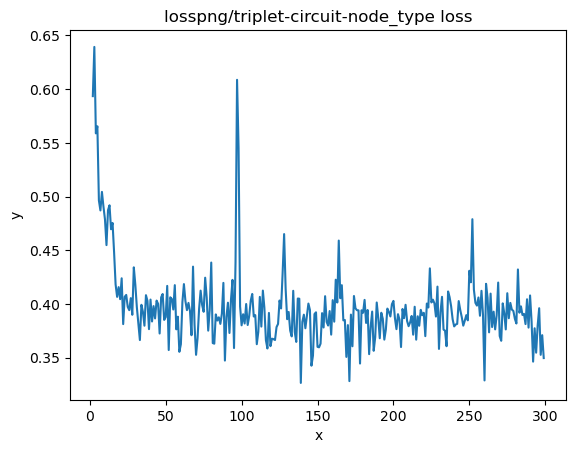

In [19]:
trainer.draw_loss('loss_value.csv','triplet-circuit-node_type loss')

In [20]:
cfg.epochs = 100
trainer.triplet_train_node_type(train_loader, mining='semihard', margin=0.2)
# trainer.triplet_train_node_type(train_loader, mining='hard', margin=0.2)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 0 Iteration 0: Loss = 0.09043202549219131, Number of mined triplets = 1543


Epoch 0 Iteration 1: Loss = 0.09490475058555603, Number of mined triplets = 1157


Epoch 0 Iteration 2: Loss = 0.071156807243824, Number of mined triplets = 635


Epoch 0 Iteration 3: Loss = 0.05335642024874687, Number of mined triplets = 607


...

Epoch 80 Iteration 1: Loss = 0.07969698309898376, Number of mined triplets = 961


Epoch 80 Iteration 2: Loss = 0.08494222164154053, Number of mined triplets = 666


 81%|████████  | 81/100 [02:45<00:38,  2.04s/it]

Epoch 80 Iteration 3: Loss = 0.07508325576782227, Number of mined triplets = 1060
Epoch 80 Iteration 4: Loss = 0.0732761025428772, Number of mined triplets = 781


100%|██████████| 100/100 [03:23<00:00,  2.04s/it]


In [21]:
tsv = os.path.join('losspng','loss_value2.csv')
# writer = csv.writer(open(tsv, 'w'))
with open(tsv, 'w') as f:
    writer = csv.writer(f)
    loss2 = trainer.loss_value
    loss2 = loss1 + loss2
    for index, line in enumerate(loss2, start=1):
        # print(line)
        writer.writerow([index, line[1]])

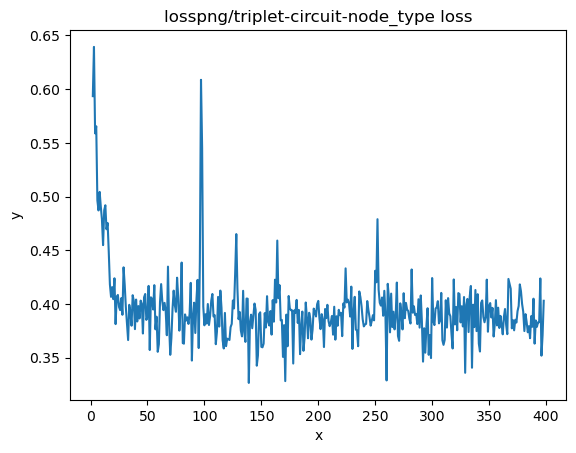

In [22]:
trainer.draw_loss('loss_value2.csv','triplet-circuit-node_type loss')

保存模型

In [23]:
# torch.save(model.state_dict(), "triplet_model.pt")
torch.save(model.state_dict(), "triplet_model_circuitgraph_node_type_good_test.pt")

## 3 评估

In [24]:
test_loss, test_labels, zz, test_preds = trainer.inference_node_type(test_loader)

100%|██████████| 29/29 [00:07<00:00,  4.13it/s]


In [25]:
trainer.metric_calc(test_loss,  test_labels,  test_preds,  header="test ")

test  loss: 0.078399, test  accuracy: 0.9525, test  f1 score: 0.7981, test  confusion_matrix: [[1571   73], [  14  172]], test  precision: 0.7020, test  recall: 0.9247


In [26]:
auc = roc_auc_score(test_labels, zz)

In [27]:
auc

0.9813234178374277

In [28]:
fpr, tpr, thresholds = roc_curve(test_labels, zz)
maxindex = (tpr - fpr).tolist().index(max(tpr - fpr))
thresholds[maxindex]

0.86937505

这个阈值很大，大于0.8，那如果还按0.5分类，FPR就会变大，导致有很多负样本被分类为正样本

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

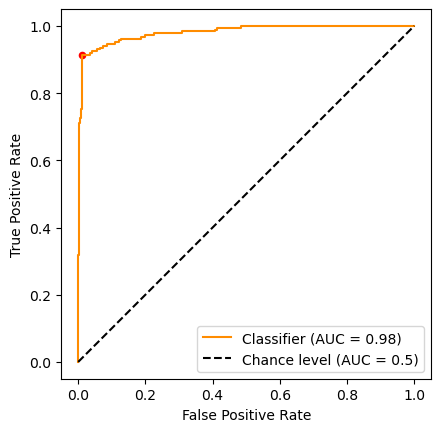

In [30]:
RocCurveDisplay.from_predictions(
    test_labels,
    zz,
    # name=f"HW2VEC",
    color="darkorange",
    plot_chance_level=True,
)
plt.axis("square")
plt.scatter(fpr[maxindex], tpr[maxindex], color='red', s=20)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
# plt.title("One-vs-Rest ROC curves:\nVirginica vs (Setosa & Versicolor)")
plt.legend()
plt.show()

ROC图放论文上应该是把两种方法的ROC曲线放一张图里比较好，看啥时候弄一下，好像还不是很好弄？

## 4 计算图可视化

In [31]:
from torchviz import make_dot

In [32]:
help(make_dot)

Help on function make_dot in module torchviz.dot:

make_dot(var, params=None, show_attrs=False, show_saved=False, max_attr_chars=50)
    Produces Graphviz representation of PyTorch autograd graph.
    
    If a node represents a backward function, it is gray. Otherwise, the node
    represents a tensor and is either blue, orange, or green:
     - Blue: reachable leaf tensors that requires grad (tensors whose `.grad`
         fields will be populated during `.backward()`)
     - Orange: saved tensors of custom autograd functions as well as those
         saved by built-in backward nodes
     - Green: tensor passed in as outputs
     - Dark green: if any output is a view, we represent its base tensor with
         a dark green node.
    
    Args:
        var: output tensor
        params: dict of (name, tensor) to add names to node that requires grad
        show_attrs: whether to display non-tensor attributes of backward nodes
            (Requires PyTorch version >= 1.9)
        show_

In [33]:
with torch.no_grad():
    trainer.model.eval()
    # trainer.model.train()

    data = dataset[0]
    data.to(cfg.device)
    label = data.label
    # print(label.type)
    embed_x, _ = trainer.model.embed_graph_node_type(data.x, data.edge_index, data.batch, data.node_type)
    embed_x = trainer.model.mlp(embed_x)

In [34]:
trainer.model.eval()
# trainer.model.train()

data = dataset[0]
data.to(cfg.device)
label = data.label
# print(label.type)
embed_x, _ = trainer.model.embed_graph_node_type(data.x, data.edge_index, data.batch, data.node_type)
embed_x = trainer.model.mlp(embed_x)

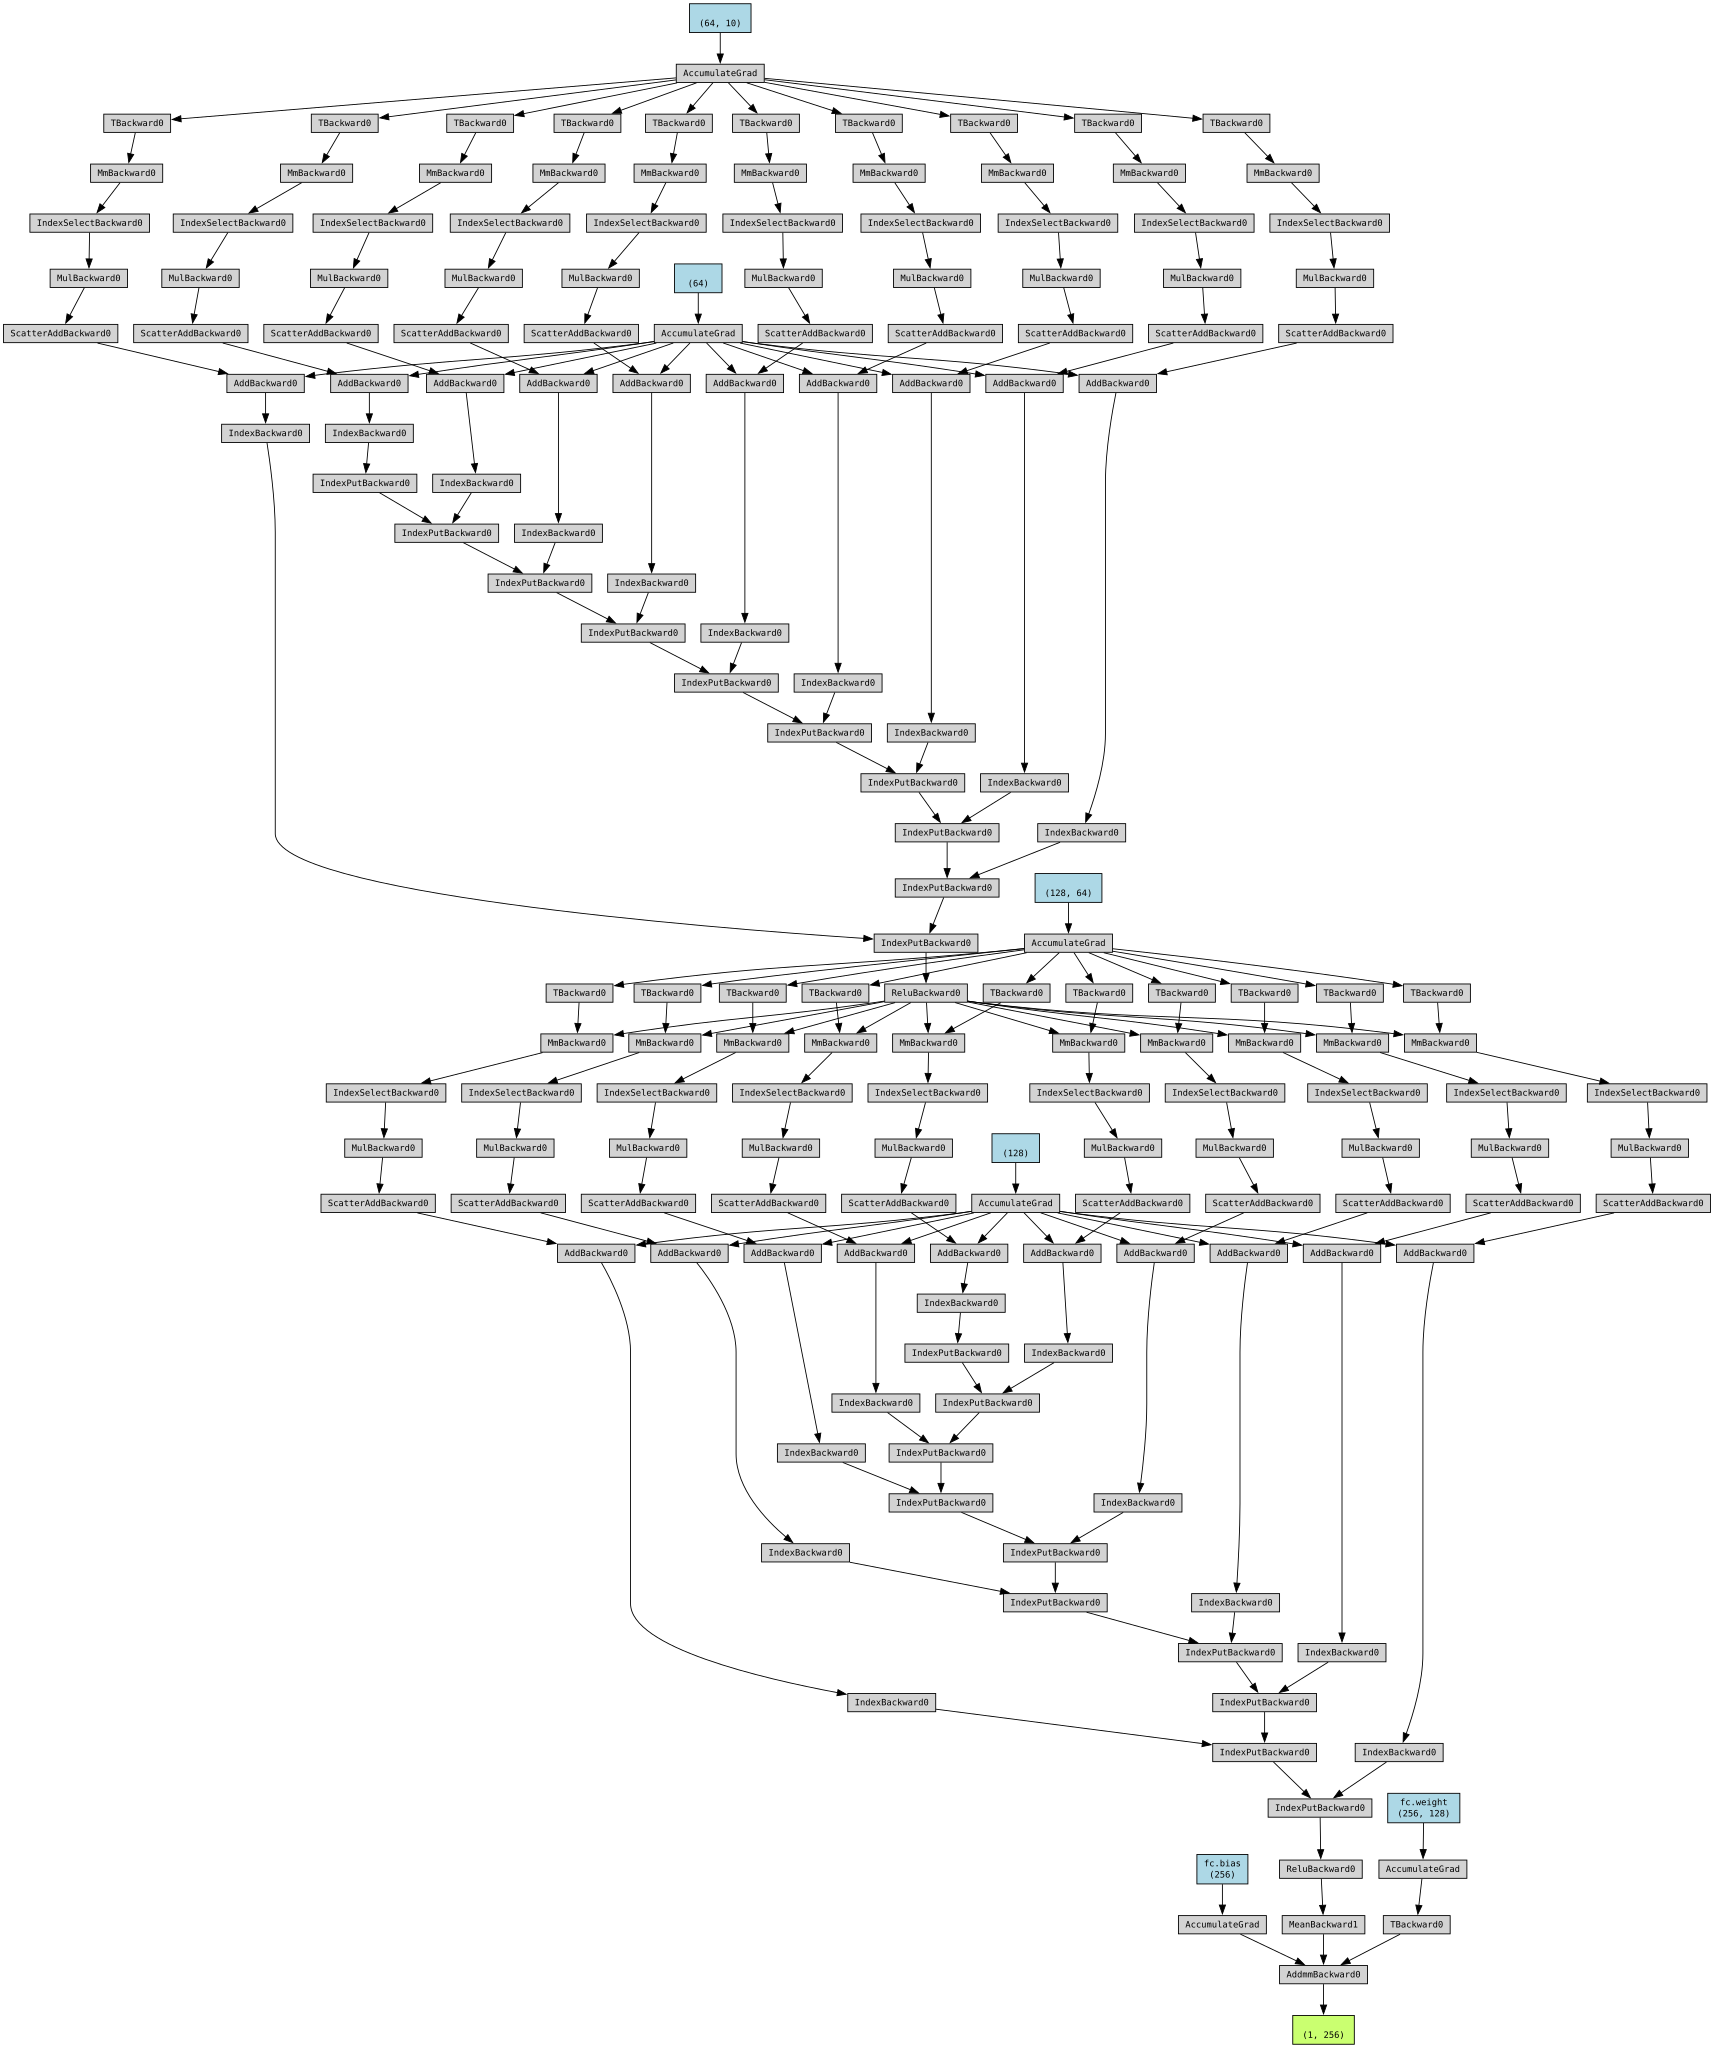

In [35]:
make_dot(embed_x, params=dict(model.named_parameters()))

In [36]:
dict(model.named_parameters)

TypeError: 'method' object is not iterable

~~好像不成？~~ 是参数传错了

In [ ]:
from torchsummary import summary

In [ ]:
data

Data(edge_index=[2, 1096], x=[619, 10], label=0, type='c1355', name='c1355', node_type=[619])

In [ ]:
summary(model, data.x.shape)

NotImplementedError: Module [GRAPH2VEC] is missing the required "forward" function

## 可视化

In [ ]:
import umap
import matplotlib.pyplot as plt
from cycler import cycler

需要先获取所有样本的特征，得按batch收集一下吧

In [ ]:
embeddings = []
labels = []

In [ ]:
with torch.no_grad():
    trainer.model.eval()

    for data in train_loader:
        data.to(cfg.device)
        label = data.label
        # print(label.type)
        embed_x, _ = trainer.model.embed_graph_node_type(data.x, data.edge_index, data.batch, data.node_type)
        embed_x = trainer.model.mlp(embed_x)
        embeddings.append(embed_x)
        labels.append(label)

In [ ]:
embeddings

[tensor([[-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         ...,
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245]],
        device='cuda:0'),
 tensor([[-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         ...,
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245],
         [-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.0245]],
        device='cuda:0'),
 tensor([[-0.0070,  0.0069,  0.0234,  ..., -0.0110, -0.0184, -0.02

In [ ]:
embeddingszz = torch.stack(embeddings[:-1], dim=3)

IndexError: Dimension out of range (expected to be in range of [-3, 2], but got 3)

In [ ]:
zz = torch.cat([embeddings[0], embeddings[1]])

In [ ]:
zz.shape

torch.Size([32, 128])

In [ ]:
embeddingszz = embeddings[0]
for e in embeddings[1:]:
    embeddingszz = torch.cat([embeddingszz, e])

In [ ]:
embeddingszz.shape

torch.Size([248, 128])

In [ ]:
labelszz = labels[0]
for e in labels[1:]:
    labelszz = torch.cat([labelszz, e])

In [ ]:
labelszz.shape

torch.Size([248])

In [ ]:
reducer = umap.UMAP()
umap_embeddings = reducer.fit_transform(embeddingszz.cpu().numpy())

得把张量从显卡移到CPU，再转为`NumPy`类型

In [ ]:
umap_embeddings.shape

(248, 2)

In [ ]:
labels = labelszz.cpu().numpy()

In [ ]:
labels

array([6, 3, 1, 8, 0, 1, 3, 3, 3, 4, 5, 2, 3, 5, 0, 0, 8, 2, 1, 0, 4, 0,
       1, 3, 6, 7, 2, 6, 1, 1, 0, 0, 5, 8, 7, 3, 1, 2, 7, 6, 5, 4, 4, 6,
       0, 4, 5, 7, 6, 5, 0, 0, 0, 0, 4, 1, 0, 0, 5, 4, 0, 3, 5, 2, 0, 7,
       6, 5, 2, 4, 2, 2, 0, 0, 0, 4, 4, 8, 2, 0, 4, 4, 8, 1, 8, 6, 1, 3,
       0, 8, 1, 0, 1, 0, 1, 1, 6, 0, 1, 2, 6, 3, 3, 2, 5, 0, 5, 8, 7, 0,
       1, 3, 8, 6, 0, 0, 0, 6, 8, 2, 2, 3, 0, 6, 5, 3, 7, 5, 3, 1, 8, 8,
       7, 6, 2, 5, 2, 2, 1, 2, 5, 3, 8, 7, 6, 4, 4, 1, 6, 2, 1, 0, 5, 1,
       4, 0, 6, 0, 0, 7, 2, 8, 0, 0, 6, 0, 2, 0, 4, 5, 3, 8, 2, 4, 0, 0,
       2, 4, 3, 0, 4, 1, 8, 2, 3, 0, 0, 0, 3, 1, 1, 5, 2, 2, 3, 0, 6, 7,
       6, 5, 0, 3, 3, 7, 0, 4, 1, 3, 3, 3, 7, 7, 1, 0, 8, 5, 3, 6, 3, 4,
       5, 4, 4, 5, 3, 1, 3, 6, 5, 1, 2, 0, 2, 5, 0, 1, 0, 2, 1, 8, 2, 6,
       5, 4, 2, 0, 7, 0], dtype=int64)

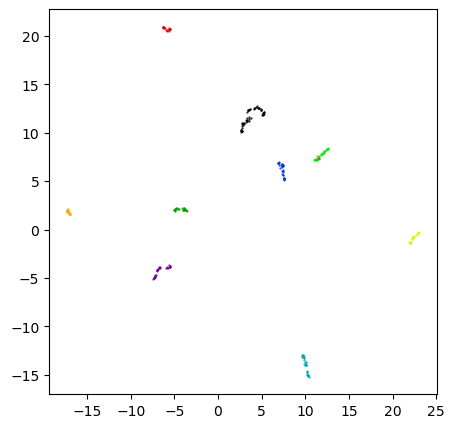

In [ ]:
label_set = np.unique(labels)
num_classes = len(label_set)
# print(num_classes, label_set)
plt.figure(figsize=(5, 5))
plt.gca().set_prop_cycle(
    cycler(
        "color", [plt.cm.nipy_spectral(i) for i in np.linspace(0, 0.9, num_classes)]
    )
)
for i in range(num_classes):
    idx = labels == label_set[i]
    # print(idx)
    plt.plot(umap_embeddings[idx, 0], umap_embeddings[idx, 1], ".", markersize=1)
# plt.colorbar(boundaries=np.arange(10)-0.5).set_ticks(np.arange(num_classes))
plt.show()

虽然效果不如PML的栗子那么明显，但是和umap官网的样例其实是很相似的，调一调图，是可以放论文里的吧？

之后可以看怎么加个图例

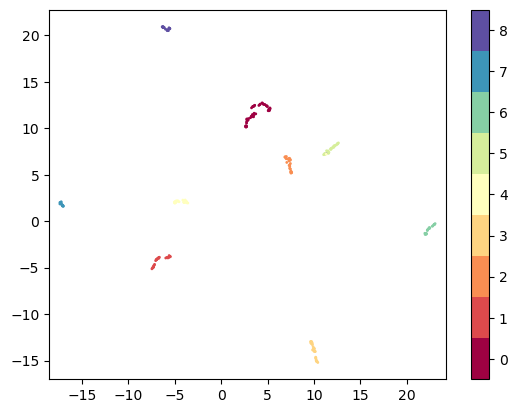

In [ ]:
plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], c=labels, cmap='Spectral', s=1, alpha=1)
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(10)-0.5).set_ticks(np.arange(num_classes))
# plt.title('UMAP projection of the Digits dataset', fontsize=24)

好多参数不知道是啥意思，论文中确定要用的话还可以再尝试美观一下。

现在足够说明度量学习的有效性了吧